# 3 - Persistence Baseline

**Purpose:** establish the forecasting error produced by assuming headcount stays unchanged for the next 30 minutes. This baseline will be used to compare the two regression models against, on the same elegible examples.

This notebook uses only the **training and validation CSVs** produced by Notebook 2. It does not open `test.csv`, fit parameters, change the data splits, or select a regression model.

A forecast made at time $t$ is
$$\hat y_{t+30\mathrm{min}}=\text{latest accepted headcount at }t.$$
The "current" and target measurements each follow Notebook 2's five minute rule ("Current" times are those at or including the time within a 5 minute window beforehand). The target is one sensor count near the future instant, not the mean count over the next 30 minutes.

**Files needed:** the prepared data folder plus `src/__init__.py` and `src/evaluation.py` from this package. 



### Import the shared source functions

In [1]:
from pathlib import Path
import sys
import json
import hashlib
import platform
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Import the shared project functions rather than copying error formulas into this notebook.
project_root = Path("..").resolve()
assert (project_root / "src" / "evaluation.py").is_file(), (
    "Expected src/evaluation.py in the project root. Check file placement and working folder."
)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.evaluation import persistence_predict, regression_metrics

print("Project root:", project_root)
print("Python:", platform.python_version(), "| pandas:", pd.__version__)

Project root: C:\Users\chris\OneDrive\Desktop\MMA3001\Project\mma3001_project
Python: 3.14.6 | pandas: 3.0.6


### Load the fixed training and validation examples


In [3]:
space_prefix = "227f1068"
data_folder = project_root / "data" / "prepared" / space_prefix
with open(data_folder / "preparation_settings.json", encoding="utf-8") as file:
    settings = json.load(file)

feature_columns = settings["feature_columns"]
target_column = settings["target_column"]
assert target_column == "target_headcount"
# Keep the future answer separate from information available when forecasting.
assert target_column not in feature_columns
assert settings["space_id"].startswith(space_prefix)
assert settings["horizon_minutes"] == 30

# Keep the final test file out of this development stage.
train = pd.read_csv(data_folder / "train.csv")
validation = pd.read_csv(data_folder / "validation.csv")
datasets = {"train": train, "validation": validation}
periods = {
    "train": (settings["train_start"], settings["validation_start"]),
    "validation": (settings["validation_start"], settings["test_start"])
}

# Check that these are the intended rows and dates before calculating errors.
for name, dataset in datasets.items():
    dataset["forecast_time"] = pd.to_datetime(dataset["forecast_time"], utc=True)
    dataset["target_time"] = pd.to_datetime(dataset["target_time"], utc=True)
    period_start, period_end = periods[name]
    assert len(dataset) == settings["split_counts"][name]
    assert len(dataset) > 0
    assert dataset["forecast_time"].is_unique
    assert dataset["forecast_time"].is_monotonic_increasing
    assert dataset[feature_columns + [target_column]].notna().all().all()
    assert (dataset["forecast_time"] >= pd.Timestamp(period_start)).all()
    assert (dataset["target_time"] < pd.Timestamp(period_end)).all()
    assert ((dataset["target_time"] - dataset["forecast_time"]) == pd.Timedelta(minutes=30)).all()
    print(f"{name}: {len(dataset):,} examples checked")

print("The final test CSV has not been opened.")

train: 14,772 examples checked
validation: 3,388 examples checked
The final test CSV has not been opened.


### Understand and check the error calculations

Testing made up observed headcounts and made up predicted headcounts to check error calculation functions

In [ ]:
# Use a small example with known answers before trusting scores from thousands of forecasts.
example_observed = [3, 5, 10]
example_predicted = [2, 7, 8]
example_scores = regression_metrics(example_observed, example_predicted)

# Allow tiny rounding differences without accepting an incorrect formula.
assert np.isclose(example_scores["mae"], 5 / 3)
assert np.isclose(example_scores["rmse"], np.sqrt(3))
print("Hand calculated example passed:", example_scores)

Hand-calculated example passed: {'mae': 1.6666666666666667, 'rmse': 1.7320508075688772}


### Making predictions using our baseline (persistance) and analysing its effectiveness


In [5]:
result_rows = []
predictions_by_split = {}

for name, dataset in datasets.items():
    # The baseline learns nothing; it predicts that the current headcount stays unchanged.
    predicted = persistence_predict(dataset["headcount_now"].to_numpy())
    observed = dataset[target_column].to_numpy()
    # Use the shared error formulas so later model scores are comparable.
    scores = regression_metrics(observed, predicted)

    result_rows.append({
        "model": "persistence",
        "split": name,
        "examples": len(dataset),
        "mae_people": scores["mae"],
        "rmse_people": scores["rmse"]
    })

    # Keep dates attached so later comparisons can verify the exact forecast rows.
    predictions = dataset[["forecast_time", "target_time", "target_headcount_observed_at"]].copy()
    predictions["observed_headcount"] = observed
    predictions["predicted_headcount"] = predicted
    predictions["residual_people"] = observed - predicted
    predictions_by_split[name] = predictions

metrics = pd.DataFrame(result_rows)
display(metrics.round(4))

,model,split,examples,mae_people,rmse_people
0,persistence,train,14772,1.2557,2.1709
1,persistence,validation,3388,0.8628,1.4057


### Measure the cost of making predictions



In [6]:
validation_current = validation["headcount_now"].to_numpy()
# Make an initial call so setup work is less likely to dominate the timing.
persistence_predict(validation_current)

batch_times = []
for repeat in range(5):
    started = perf_counter()
    # Repeat this small calculation to reduce the influence of timer noise.
    for batch in range(100):
        persistence_predict(validation_current)
    seconds_per_batch = (perf_counter() - started) / 100
    batch_times.append(seconds_per_batch)

# Report a typical batch time; dividing by rows is not the latency of one live forecast.
median_seconds = float(np.median(batch_times))
timing = pd.DataFrame([{
    "model": "persistence",
    "split": "validation",
    "examples_per_batch": len(validation),
    "median_batch_seconds": median_seconds,
    "microseconds_per_example": median_seconds / len(validation) * 1_000_000,
    "repeats": 5,
    "batches_per_repeat": 100
}])
display(timing)

,model,split,examples_per_batch,median_batch_seconds,microseconds_per_example,repeats,batches_per_repeat
0,persistence,validation,3388,0.000008,0.002214,5,100


### Inspect a fixed validation window

A plot of the first calenderweek of the validation period. The horizontal axis is the **target time**, so each forecast is shown alongside its future reference observation.

**Note:** Points are not joined across missing periods. Blank areas mean no eligible evaluated examples, not zero occupancy.

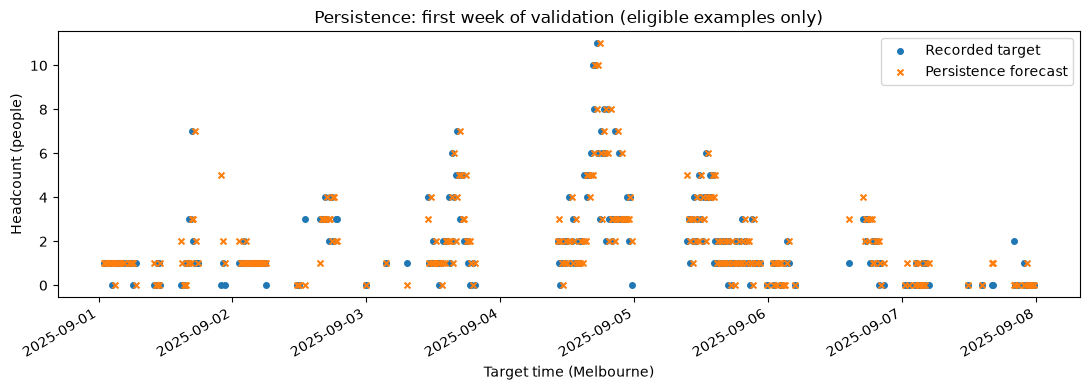

,mean_residual_people,underprediction_percent,exact_prediction_percent,overprediction_percent
0,-0.044,26.978,44.097,28.926


In [7]:
validation_predictions = predictions_by_split["validation"]
# Use a fixed week rather than selecting a period where the baseline looks best.
week_start = pd.Timestamp(settings["validation_start"])
week_end = week_start + pd.Timedelta(days=7)
plot_data = validation_predictions[
    (validation_predictions["target_time"] >= week_start)
    & (validation_predictions["target_time"] < week_end)
]
plot_times = plot_data["target_time"].dt.tz_convert("Australia/Melbourne")

fig, ax = plt.subplots(figsize=(11, 4))
# Leave gaps unconnected so the plot does not imply observations where none exist.
ax.scatter(plot_times, plot_data["observed_headcount"], s=16, label="Recorded target")
ax.scatter(plot_times, plot_data["predicted_headcount"], s=18, marker="x", label="Persistence forecast")
ax.set_title("Persistence: first week of validation (eligible examples only)")
ax.set_xlabel("Target time (Melbourne)")
ax.set_ylabel("Headcount (people)")
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

# Positive residuals mean the forecast was too low; negative values mean it was too high.
residuals = validation_predictions["residual_people"]
direction_summary = pd.DataFrame([{
    "mean_residual_people": residuals.mean(),
    "underprediction_percent": 100 * (residuals > 0).mean(),
    "exact_prediction_percent": 100 * (residuals == 0).mean(),
    "overprediction_percent": 100 * (residuals < 0).mean()
}])
display(direction_summary.round(3))

### Save the baseline evidence

In [9]:
output_folder = project_root / "outputs" / space_prefix / "persistence"
output_folder.mkdir(parents=True, exist_ok=True)

metrics.to_csv(output_folder / "metrics.csv", index=False)
timing.to_csv(output_folder / "timing.csv", index=False)
direction_summary.to_csv(output_folder / "validation_error_direction.csv", index=False)
# Retain individual forecasts so the final comparison can check row alignment.
for name, predictions in predictions_by_split.items():
    predictions.to_csv(output_folder / f"{name}_predictions.csv", index=False)
fig.savefig(output_folder / "validation_first_week.png", dpi=160, bbox_inches="tight")

# Record file contents and settings so later comparisons can detect changed inputs.
fingerprints = {}
for name in datasets:
    fingerprints[name] = hashlib.sha256((data_folder / f"{name}.csv").read_bytes()).hexdigest()
run_information = {
    "model": "persistence",
    "rule": "Forecast equals the latest accepted current headcount; no fitting",
    "space_id": settings["space_id"],
    "horizon_minutes": settings["horizon_minutes"],
    "evaluated_partitions": list(datasets),
    "test_data_used": False,
    "csv_sha256": fingerprints,
    "preparation_settings": settings,
    "python_version": platform.python_version(),
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "timing_scope": "persistence_predict on existing validation array, including checks and copy"
}
with open(output_folder / "run_information.json", "w", encoding="utf-8") as file:
    json.dump(run_information, file, indent=2)

print("Saved baseline results to:", output_folder)
print("No final test predictions have been made.")

Saved baseline results to: C:\Users\chris\OneDrive\Desktop\MMA3001\Project\mma3001_project\outputs\227f1068\persistence
No final test predictions have been made.
